In [1]:
library('tidyverse')

── Attaching core tidyverse packages ─────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     ── Conflicts ───────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

In [2]:
llm = read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/refs/heads/main/data/llm_usage.csv')

llm |> head()

  student date       hour weekday prompt_tokens cached_tokens completion_tokens
1 s00ccbf 2026-10-05 11   Mon     14930         14524          36              
2 s00ccbf 2026-10-05 11   Mon     14654         14360          58              
3 s00ccbf 2026-10-05 11   Mon     14490         14238         118              
4 s00ccbf 2026-10-05 11   Mon     14368         14004          92              
5 s00ccbf 2026-10-05 11   Mon     14133         13750          58              
6 s00ccbf 2026-10-05 11   Mon     13880         13706         243              
  cost_usd latency_s success
1 0.000252 0.9       True   
2 0.000244 1.5       True   
3 0.000303 1.6       True   
4 0.000304 1.9       True   
5 0.000267 1.3       True   
6 0.000426 2.9       True   

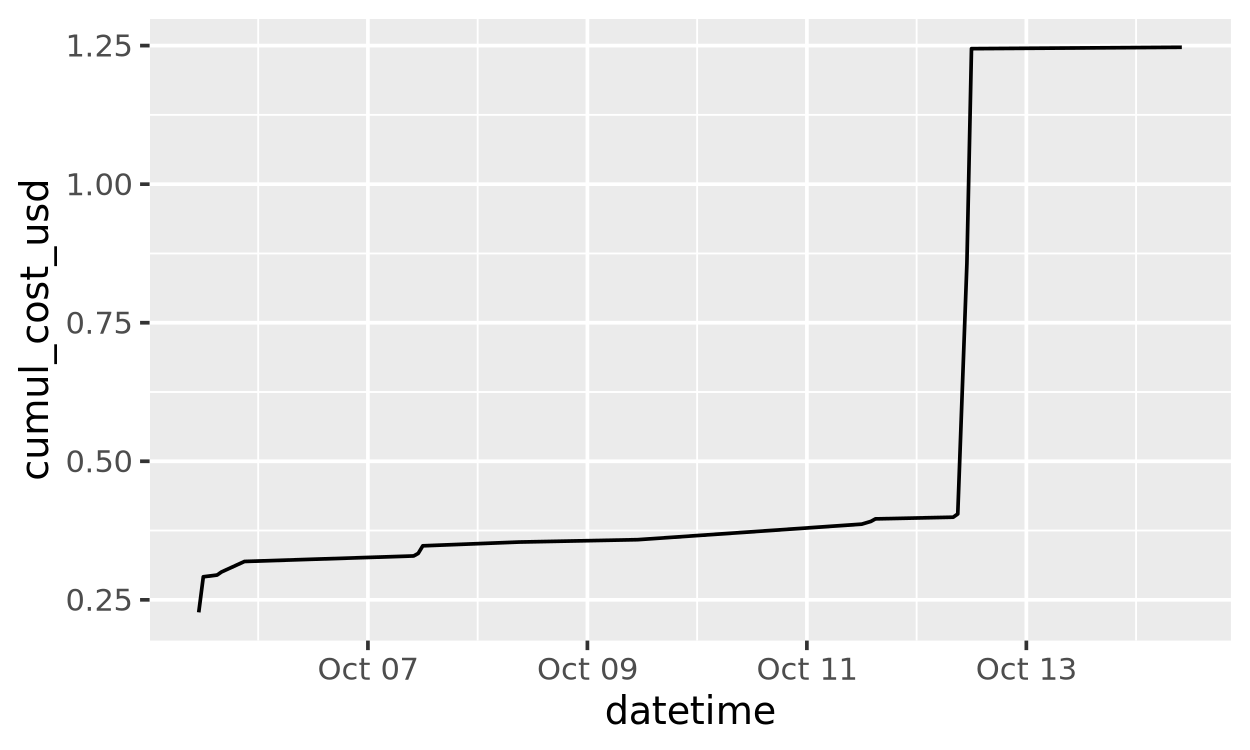

In [8]:
llm |>
    mutate(datetime = ymd(date) + hours(hour)) |>
    group_by(datetime) |>
    summarise(cost_usd = sum(cost_usd)) |>
    arrange(datetime) |>
    mutate(cumul_cost_usd = cumsum(cost_usd)) |>
ggplot(aes(x = datetime, y = cumul_cost_usd)) + geom_line()

In [16]:
llm |>
    mutate(
        datetime = ymd(date) + hours(hour),
        day = date(date)
    ) |>
    group_by(day) |>
    summarize(cost = sum(cost_usd)) |>
    arrange(day) |>
    mutate(cumul_cost_usd = cumsum(cost))
#     group_by(datetime) |>
#     summarise(cost_usd = sum(cost_usd)) |>
#     arrange(datetime) |>
#     mutate(cumul_cost_usd = cumsum(cost_usd)) |>
# ggplot(aes(x = datetime, y = cumul_cost_usd)) + geom_line()

  day        cost     cumul_cost_usd
1 2026-10-05 0.319199 0.319199      
2 2026-10-07 0.028235 0.347434      
3 2026-10-08 0.006794 0.354228      
4 2026-10-09 0.004286 0.358514      
5 2026-10-11 0.037544 0.396058      
6 2026-10-12 0.848426 1.244484      
7 2026-10-14 0.002500 1.246984      

In [4]:
llm |> glimpse()

Rows: 1,299
Columns: 10
$ student           <chr> "s00ccbf", "s00ccbf", "s00ccbf", "s00ccbf", "s00ccbf…
$ date              <chr> "2026-10-05", "2026-10-05", "2026-10-05", "2026-10-0…
$ hour              <int> 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, …
$ weekday           <chr> "Mon", "Mon", "Mon", "Mon", "Mon", "Mon", "Mon", "Mo…
$ prompt_tokens     <int> 14930, 14654, 14490, 14368, 14133, 13880, 13836, 136…
$ cached_tokens     <int> 14524, 14360, 14238, 14004, 13750, 13706, 13536, 133…
$ completion_tokens <int> 36, 58, 118, 92, 58, 243, 24, 58, 155, 64, 130, 131,…
$ cost_usd          <dbl> 0.000252, 0.000244, 0.000303, 0.000304, 0.000267, 0.…
$ latency_s         <dbl> 0.9, 1.5, 1.6, 1.9, 1.3, 2.9, 1.5, 1.5, 2.2, 1.4, 1.…
$ success           <chr> "True", "True", "True", "True", "True", "True", "Tru…


In [6]:
llm |> summarize(n_distinct = n_distinct(student))

  n_distinct
1 27        